# Harris Corner Detection

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

from harris import get_harris_corners

# 图片路径
folder = "./images"
filename = "image1.jpg"
image_path = os.path.join(folder, filename)

# 读取图片
im = np.array(Image.open(image_path).convert("L"))

print("Image shape:", im.shape)

Image shape: (1280, 1707)


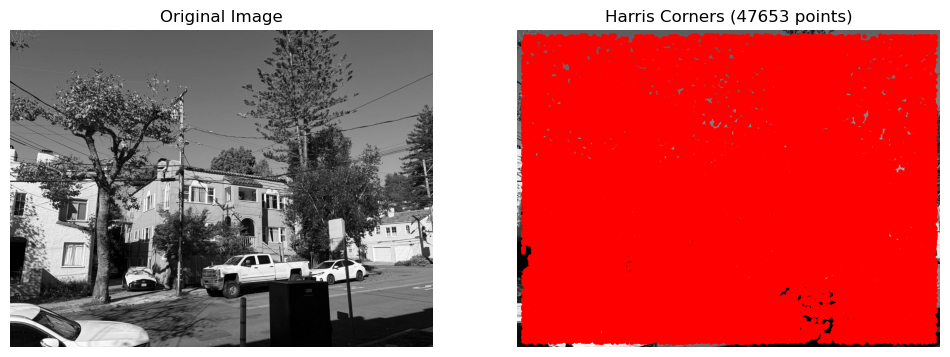

In [28]:
from harris import get_harris_corners
# Harris corner detection
h, coords = get_harris_corners(im)

# coords 的形状是 (2, N)，分别对应 y 和 x
ys, xs = coords

# Visualize
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(im, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(im, cmap="gray")
plt.scatter(xs, ys, s=5, c="red", marker="o")
plt.title(f"Harris Corners ({len(xs)} points)")
plt.axis("off")

plt.show()

In [29]:
from scipy.spatial import cKDTree
import numpy as np

def anms(h, coords, num_points=500, c_robust=0.9):

    ys, xs = coords
    points = np.column_stack((xs, ys))
    strengths = h[ys, xs]

    n = len(points)
    tree = cKDTree(points)

    radii = np.full(n, np.inf)
    unresolved = np.arange(n)
    k = min(16, n)

    while len(unresolved) > 0:

        distances, indices = tree.query(
            points[unresolved], k=k
        )

        if k == 1:
            distances = distances[:, None]
            indices = indices[:, None]

        # Exclude the point itself
        not_self = indices != unresolved[:, None]

        # Find sufficiently stronger neighbors
        stronger = (
            not_self &
            (strengths[indices] >
             c_robust * strengths[unresolved, None])
        )

        found = stronger.any(axis=1)

        if np.any(found):
            first = np.argmax(stronger[found], axis=1)

            radii[unresolved[found]] = (
                distances[found, first]
            )

        unresolved = unresolved[~found]

        if len(unresolved) > 0:
            if k == n:
                break
            k = min(k * 2, n)

    selected_indices = np.argsort(radii)[::-1][:num_points]

    return coords[:, selected_indices]

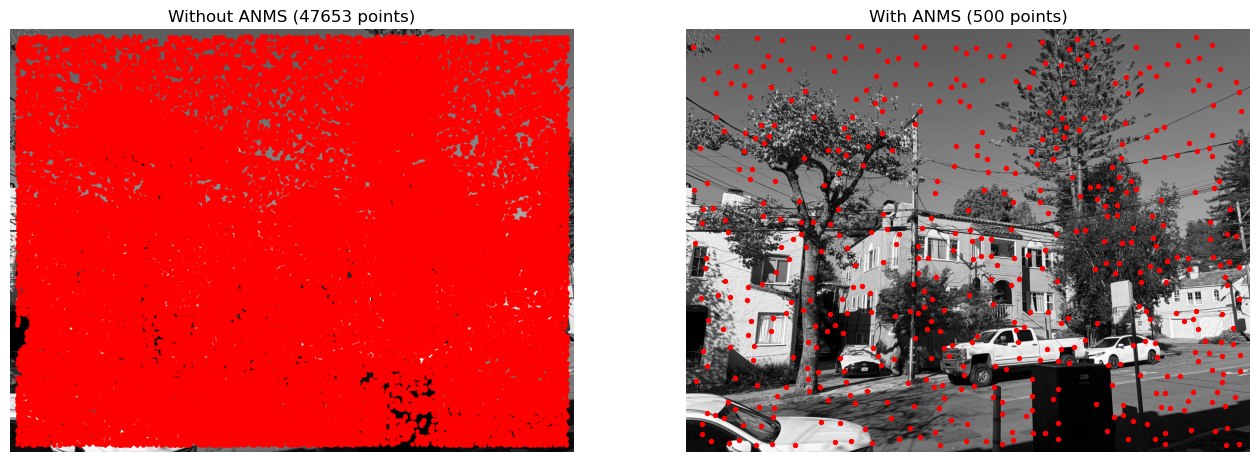

In [30]:
# Detect Harris corners
h, coords = get_harris_corners(im)

# Apply ANMS
selected_coords = anms(
    h,
    coords,
    num_points=500,
    c_robust=0.9
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Without ANMS
axes[0].imshow(im, cmap="gray")
axes[0].scatter(coords[1], coords[0], s=5, c="red")
axes[0].set_title(f"Without ANMS ({coords.shape[1]} points)")
axes[0].axis("off")

# With ANMS
axes[1].imshow(im, cmap="gray")
axes[1].scatter(selected_coords[1], selected_coords[0],
                s=8, c="red")
axes[1].set_title(f"With ANMS ({selected_coords.shape[1]} points)")
axes[1].axis("off")

plt.show()

# Feature Descriptor Extraction

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, map_coordinates


def get_feature_descriptors(im, coords, blur_sigma=2.0):

    # Convert image to float
    im = np.asarray(im, dtype=np.float64)

    # Gaussian blur
    blurred = gaussian_filter(im, sigma=blur_sigma)

    ys, xs = coords
    n = len(xs)

    patches = []

    # Sampling positions: 8 pixels, spacing = 5
    offsets = (np.arange(8) - 3.5) * 5

    for y, x in zip(ys, xs):

        # Generate 8x8 sampling coordinates
        yy, xx = np.meshgrid(
            y + offsets,
            x + offsets,
            indexing="ij"
        )

        # Bilinear interpolation
        patch = map_coordinates(
            blurred,
            [yy, xx],
            order=1,
            mode="nearest"
        )

        # Bias/Gain normalization
        mean = patch.mean()
        std = patch.std()

        if std > 1e-8:
            patch = (patch - mean) / std
        else:
            patch = np.zeros_like(patch)

        patches.append(patch)

    patches = np.array(patches)

    # Flatten each 8x8 patch into a 64-dimensional vector
    descriptors = patches.reshape(n, 64)

    return descriptors, patches

In [32]:
descriptors, patches = get_feature_descriptors(
    im,
    selected_coords
)

print("Number of features:", len(descriptors))
print("Descriptor shape:", descriptors.shape)
print("Patches shape:", patches.shape)

Number of features: 500
Descriptor shape: (500, 64)
Patches shape: (500, 8, 8)


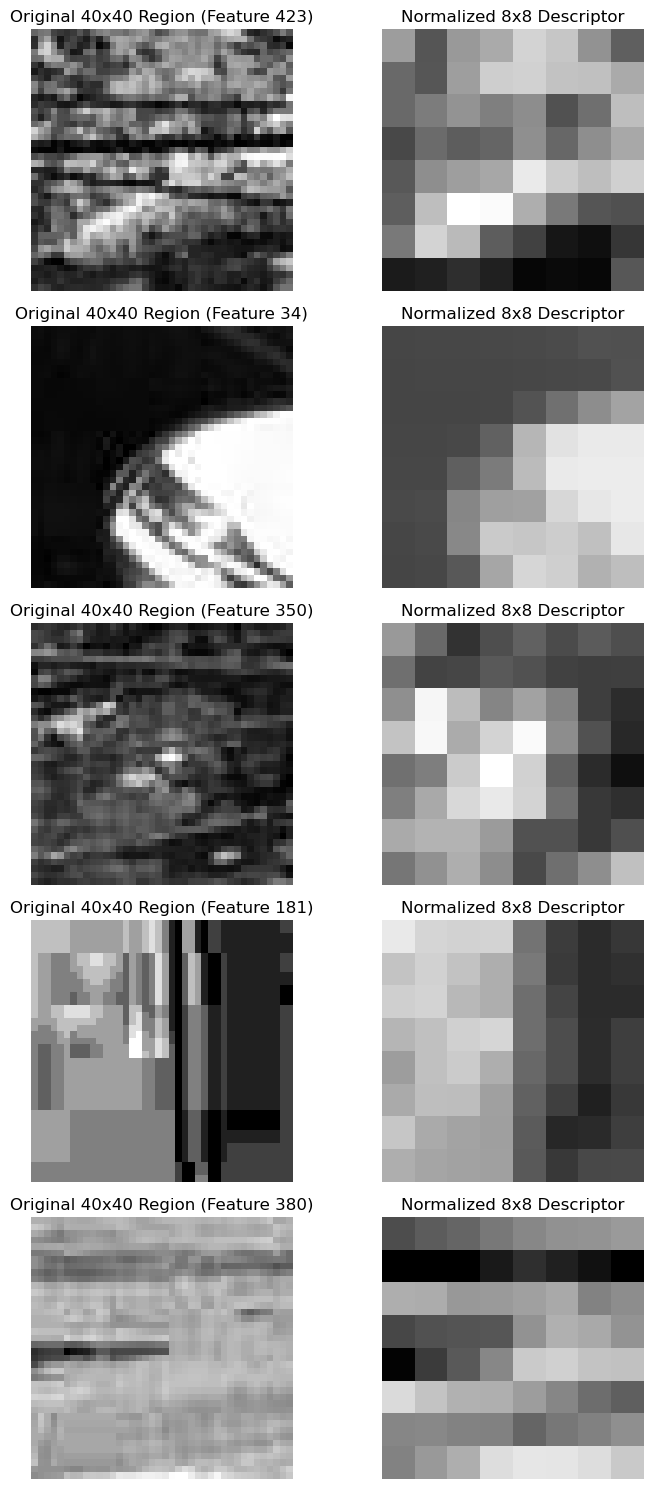

In [33]:
# Randomly select 5 features
num_show = min(5, len(patches))
random_indices = np.random.choice(
    len(patches),
    num_show,
    replace=False
)

fig, axes = plt.subplots(
    num_show, 2,
    figsize=(8, 3 * num_show)
)

if num_show == 1:
    axes = axes.reshape(1, 2)

for row, idx in enumerate(random_indices):

    y, x = selected_coords[:, idx]

    # Extract the original 40x40 region for visualization
    region = im[
        y - 20:y + 20,
        x - 20:x + 20
    ]

    # Original local region
    axes[row, 0].imshow(region, cmap="gray")
    axes[row, 0].set_title(f"Original 40x40 Region (Feature {idx})")
    axes[row, 0].axis("off")

    # Normalized 8x8 descriptor
    axes[row, 1].imshow(
        patches[idx],
        cmap="gray",
        interpolation="nearest",
        vmin=-2,
        vmax=2
    )
    axes[row, 1].set_title("Normalized 8x8 Descriptor")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

# Feature Matching

In [ ]:
import numpy as np
from harris import dist2


def match_features(desc1, desc2, ratio_thresh=0.8):

    if len(desc2) < 2:
        raise ValueError("Image 2 must contain at least two descriptors.")

    # Compute squared Euclidean distance matrix
    distances_sq = dist2(desc1, desc2)

    # Convert squared distances to Euclidean distances
    distances = np.sqrt(np.maximum(distances_sq, 0))

    # Find two nearest neighbors in image 2 for each descriptor
    nearest_indices = np.argsort(distances, axis=1)[:, :2]

    # Get the two nearest distances
    rows = np.arange(len(desc1))

    d1 = distances[rows, nearest_indices[:, 0]]
    d2 = distances[rows, nearest_indices[:, 1]]

    # Compute Lowe's ratio
    ratios_all = d1 / np.maximum(d2, 1e-10)

    # Keep matches passing the ratio test
    valid = ratios_all < ratio_thresh

    matches = np.column_stack((
        rows[valid],
        nearest_indices[valid, 0]
    ))

    ratios = ratios_all[valid]

    return matches, ratios

In [35]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load two grayscale images
folder = "./images"

im1 = np.array(
    Image.open(os.path.join(folder, "image1.jpg")).convert("L")
)

im2 = np.array(
    Image.open(os.path.join(folder, "image2.jpg")).convert("L")
)


# B.1: Harris Corner Detection + ANMS
h1, coords1 = get_harris_corners(im1)
h2, coords2 = get_harris_corners(im2)

selected_coords1 = anms(h1, coords1, num_points=500)
selected_coords2 = anms(h2, coords2, num_points=500)


# B.2: Feature Descriptor Extraction
descriptors1, patches1 = get_feature_descriptors(
    im1, selected_coords1
)

descriptors2, patches2 = get_feature_descriptors(
    im2, selected_coords2
)


# Check results
print("Image 1:", im1.shape, descriptors1.shape)
print("Image 2:", im2.shape, descriptors2.shape)

Image 1: (1280, 1707) (500, 64)
Image 2: (1280, 1707) (500, 64)


In [36]:
# Image 1
descriptors1, patches1 = get_feature_descriptors(
    im1, selected_coords1
)

# Image 2
descriptors2, patches2 = get_feature_descriptors(
    im2, selected_coords2
)

# Feature matching
matches, ratios = match_features(
    descriptors1,
    descriptors2,
    ratio_thresh=0.8
)

print("Image 1 features:", len(descriptors1))
print("Image 2 features:", len(descriptors2))
print("Number of good matches:", len(matches))

Image 1 features: 500
Image 2 features: 500
Number of good matches: 192


In [37]:
import matplotlib.pyplot as plt


def plot_matches(im1, im2, coords1, coords2, matches,
                 max_matches=100):

    h1, w1 = im1.shape
    h2, w2 = im2.shape

    canvas = np.zeros(
        (max(h1, h2), w1 + w2),
        dtype=np.float64
    )

    canvas[:h1, :w1] = im1
    canvas[:h2, w1:w1+w2] = im2

    plt.figure(figsize=(16, 8))
    plt.imshow(canvas, cmap="gray")

    # Display a subset of matches
    shown = matches[:max_matches]

    for idx1, idx2 in shown:

        y1, x1 = coords1[:, idx1]
        y2, x2 = coords2[:, idx2]

        x2_shifted = x2 + w1

        plt.plot(
            [x1, x2_shifted],
            [y1, y2],
            linewidth=0.7
        )

        plt.scatter([x1, x2_shifted],
                    [y1, y2],
                    s=10)

    plt.title(f"Feature Matches: {len(matches)} good matches")
    plt.axis("off")
    plt.show()

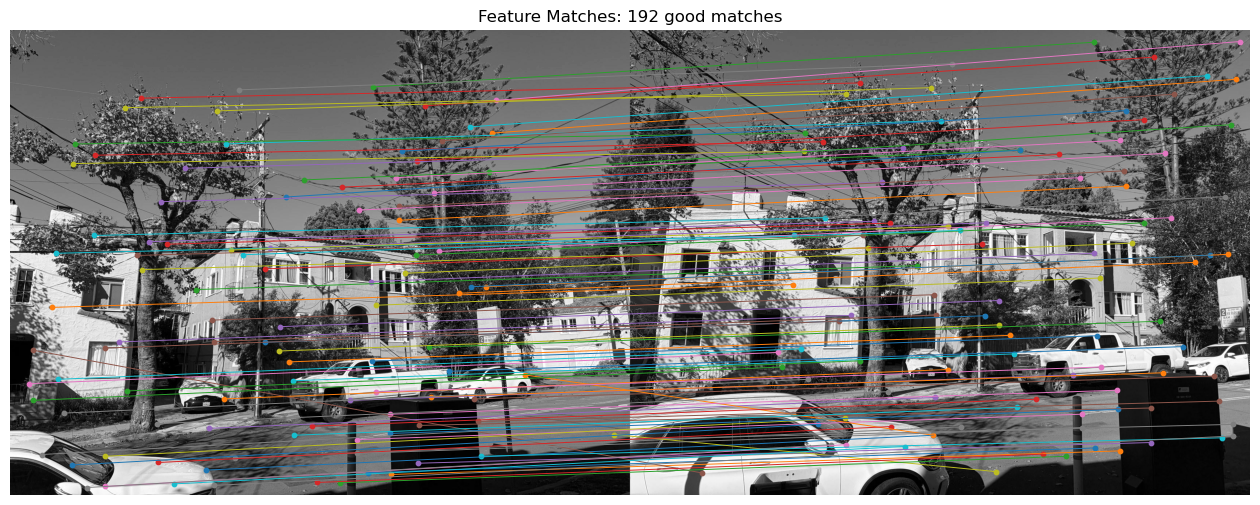

In [38]:
plot_matches(
    im1,
    im2,
    selected_coords1,
    selected_coords2,
    matches
)

# RANSAC for Robust Homography

In [ ]:

def normalize_points(points):
    centroid = np.mean(points, axis=0)
    centered = points - centroid

    mean_dist = np.mean(np.sqrt(np.sum(centered ** 2, axis=1)))
    scale = np.sqrt(2) / max(mean_dist, 1e-10)

    T = np.array([
        [scale, 0, -scale * centroid[0]],
        [0, scale, -scale * centroid[1]],
        [0, 0, 1]
    ])

    points_h = np.column_stack([
        points,
        np.ones(len(points))
    ])

    normalized = (T @ points_h.T).T

    return normalized[:, :2], T


def computeH(pts1, pts2):

    pts1 = np.asarray(pts1, dtype=float)
    pts2 = np.asarray(pts2, dtype=float)

    if pts1.shape != pts2.shape or pts1.ndim != 2 or pts1.shape[1] != 2:
        raise ValueError("pts1 and pts2 must both have shape N x 2.")

    if len(pts1) < 4:
        raise ValueError("At least four point correspondences are required.")

    # Normalize coordinates
    p1_norm, T1 = normalize_points(pts1)
    p2_norm, T2 = normalize_points(pts2)

    # Construct the DLT matrix
    A = []

    for (x, y), (xp, yp) in zip(p1_norm, p2_norm):

        A.append([
            -x, -y, -1,
             0,  0,  0,
             xp*x, xp*y, xp
        ])

        A.append([
             0,  0,  0,
            -x, -y, -1,
             yp*x, yp*y, yp
        ])

    A = np.asarray(A)

    # Solve Ah = 0 using SVD
    # full_matrices=True is important for the 8 x 9 case
    _, _, Vh = np.linalg.svd(A, full_matrices=True)

    H_norm = Vh[-1].reshape(3, 3)

    # Denormalize homography
    H = np.linalg.inv(T2) @ H_norm @ T1

    # Normalize the scale of H
    if abs(H[2, 2]) > 1e-10:
        H = H / H[2, 2]
    else:
        H = H / np.linalg.norm(H)

    return H

In [ ]:

def compute_reprojection_errors(H, pts1, pts2):
    pts1 = np.asarray(pts1, dtype=float)
    pts2 = np.asarray(pts2, dtype=float)

    # Convert points to homogeneous coordinates
    pts1_h = np.column_stack([
        pts1,
        np.ones(len(pts1))
    ])

    # Transform points using H
    projected_h = (H @ pts1_h.T).T

    # Avoid division by zero
    denominator = projected_h[:, 2]
    valid = np.abs(denominator) > 1e-10

    projected = np.full((len(pts1), 2), np.nan)
    projected[valid] = (
        projected_h[valid, :2] /
        denominator[valid, None]
    )

    # Euclidean distance
    errors = np.full(len(pts1), np.inf)
    errors[valid] = np.linalg.norm(
        projected[valid] - pts2[valid],
        axis=1
    )

    return errors

In [ ]:
def ransac_homography(
    pts1,
    pts2,
    num_iterations=2000,
    threshold=4.0
):
    pts1 = np.asarray(pts1, dtype=float)
    pts2 = np.asarray(pts2, dtype=float)

    if len(pts1) != len(pts2):
        raise ValueError("pts1 and pts2 must have the same length.")

    if len(pts1) < 4:
        raise ValueError("At least four matches are required.")

    n = len(pts1)

    best_H = None
    best_inliers = None
    best_count = 0

    for _ in range(num_iterations):

        # Randomly select four correspondences
        sample_indices = np.random.choice(
            n, 4, replace=False
        )

        sample_pts1 = pts1[sample_indices]
        sample_pts2 = pts2[sample_indices]

        # Estimate homography from four pairs
        try:
            H = computeH(sample_pts1, sample_pts2)
        except (ValueError, np.linalg.LinAlgError):
            continue

        if not np.all(np.isfinite(H)):
            continue

        # Compute reprojection errors
        errors = compute_reprojection_errors(
            H, pts1, pts2
        )

        # Find inliers
        inliers = errors < threshold
        count = np.sum(inliers)

        # Keep the model with the most inliers
        if count > best_count:
            best_count = count
            best_H = H
            best_inliers = inliers

    if best_H is None or best_count < 4:
        raise RuntimeError("RANSAC failed to find a valid homography.")

    # Recompute H using all inliers
    best_H = computeH(
        pts1[best_inliers],
        pts2[best_inliers]
    )

    return best_H, best_inliers

In [50]:
pts1 = selected_coords1[:, matches[:, 0]].T[:, [1, 0]]
pts2 = selected_coords2[:, matches[:, 1]].T[:, [1, 0]]

print("pts1 shape:", pts1.shape)
print("pts2 shape:", pts2.shape)
H, inliers = ransac_homography(
    pts1,
    pts2,
    num_iterations=2000,
    threshold=4.0
)

print("Homography:")
print(H)

print("Total matches:", len(matches))
print("Inliers:", np.sum(inliers))
print("Inlier ratio:", np.mean(inliers))

pts1 shape: (192, 2)
pts2 shape: (192, 2)
Homography:
[[ 7.52690721e-01  6.82248525e-02  3.16164246e+02]
 [-1.24520323e-01  9.36661062e-01  8.54581689e+00]
 [-1.58808360e-04  4.02169055e-05  1.00000000e+00]]
Total matches: 192
Inliers: 178
Inlier ratio: 0.9270833333333334


In [51]:
import matplotlib.pyplot as plt

def plot_ransac_matches(im1, im2, pts1, pts2, inliers):
    h1, w1 = im1.shape
    h2, w2 = im2.shape

    canvas = np.zeros(
        (max(h1, h2), w1 + w2),
        dtype=np.uint8
    )

    canvas[:h1, :w1] = im1
    canvas[:h2, w1:w1+w2] = im2

    plt.figure(figsize=(16, 8))
    plt.imshow(canvas, cmap="gray")

    for i in range(len(pts1)):
        x1, y1 = pts1[i]
        x2, y2 = pts2[i]

        color = "lime" if inliers[i] else "red"

        plt.plot(
            [x1, x2 + w1],
            [y1, y2],
            color=color,
            linewidth=0.6
        )

    plt.axis("off")
    plt.title(
        f"RANSAC: {np.sum(inliers)} inliers / {len(inliers)} matches"
    )
    plt.show()

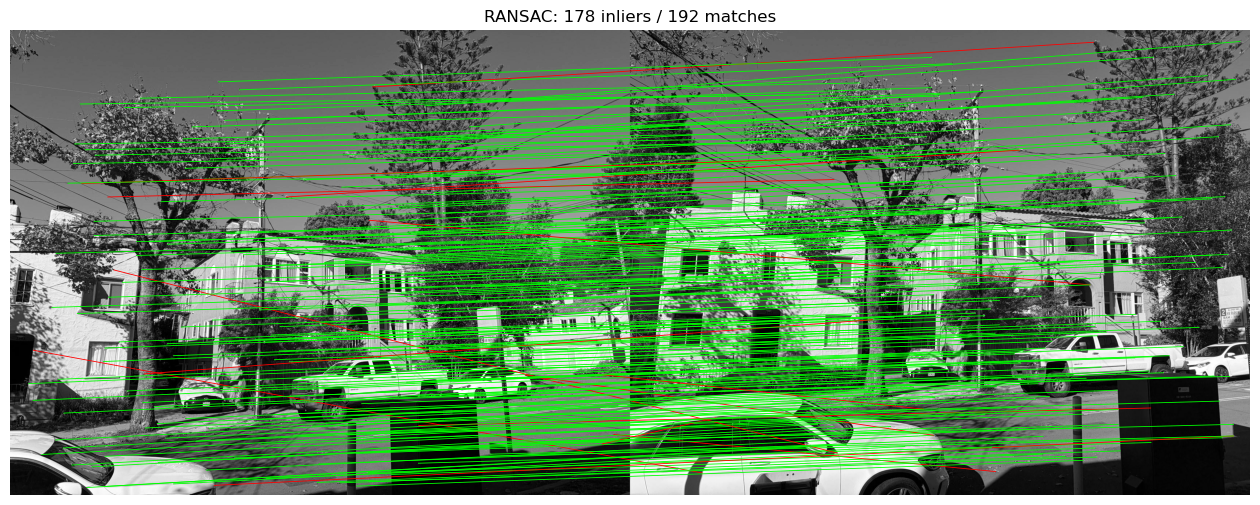

In [52]:
plot_ransac_matches(
    im1, im2,
    pts1, pts2,
    inliers
)

Image 1: (1280, 1707, 3)
Image 2: (1280, 1707, 3)
Output canvas: (1560, 2196)
warped1_rgb: (1560, 2196, 3)
warped2_rgb: (1560, 2196, 3)
weight1: (1560, 2196)
weight2: (1560, 2196)
mosaic_rgb: (1560, 2196, 3)


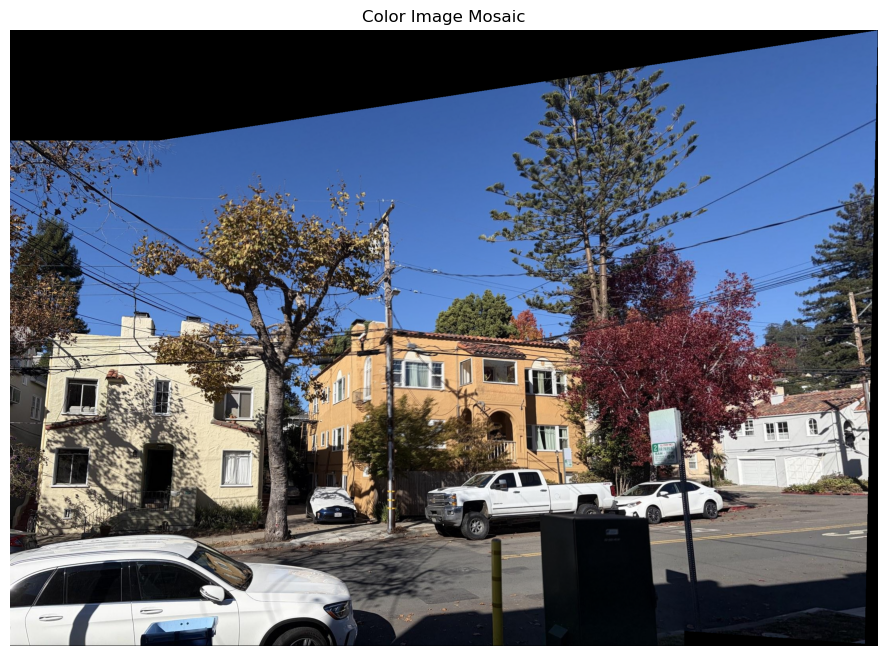

In [ ]:


import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# Reload original color images

folder = "./images"

img1_rgb = np.array(
    Image.open(os.path.join(folder, "image1.jpg")).convert("RGB")
).astype(np.float32)

img2_rgb = np.array(
    Image.open(os.path.join(folder, "image2.jpg")).convert("RGB")
).astype(np.float32)

print("Image 1:", img1_rgb.shape)
print("Image 2:", img2_rgb.shape)


# Compute output canvas bounds

def transform_corners(im, H):
    h, w = im.shape[:2]

    corners = np.array([
        [0, 0, 1],
        [w - 1, 0, 1],
        [0, h - 1, 1],
        [w - 1, h - 1, 1]
    ]).T

    transformed = H @ corners
    transformed /= transformed[2]

    return transformed[:2].T


corners1 = transform_corners(img1_rgb, H)
corners2 = transform_corners(img2_rgb, np.eye(3))

all_corners = np.vstack([corners1, corners2])

min_x = int(np.floor(np.min(all_corners[:, 0])))
min_y = int(np.floor(np.min(all_corners[:, 1])))
max_x = int(np.ceil(np.max(all_corners[:, 0])))
max_y = int(np.ceil(np.max(all_corners[:, 1])))

out_w = max_x - min_x + 1
out_h = max_y - min_y + 1

# Translation matrix: move all coordinates into positive range
T = np.array([
    [1, 0, -min_x],
    [0, 1, -min_y],
    [0, 0, 1]
], dtype=np.float64)

print("Output canvas:", (out_h, out_w))


# Bilinear interpolation for RGB images

def warp_color_image(im, H, out_size):
    out_w, out_h = out_size
    h, w, c = im.shape

    result = np.zeros((out_h, out_w, c), dtype=np.float32)

    # Inverse mapping
    H_inv = np.linalg.inv(H)

    xs, ys = np.meshgrid(
        np.arange(out_w),
        np.arange(out_h)
    )

    dest = np.stack([
        xs.ravel(),
        ys.ravel(),
        np.ones(out_w * out_h)
    ])

    src = H_inv @ dest
    src /= src[2]

    x = src[0]
    y = src[1]

    valid = (
        (x >= 0) & (x < w - 1) &
        (y >= 0) & (y < h - 1)
    )

    x0 = np.floor(x).astype(int)
    y0 = np.floor(y).astype(int)

    x0 = np.clip(x0, 0, w - 2)
    y0 = np.clip(y0, 0, h - 2)

    dx = (x - x0)[:, None]
    dy = (y - y0)[:, None]

    # Four neighboring pixels
    Ia = im[y0,     x0]
    Ib = im[y0,     x0 + 1]
    Ic = im[y0 + 1, x0]
    Id = im[y0 + 1, x0 + 1]

    # Bilinear interpolation
    values = (
        Ia * (1 - dx) * (1 - dy) +
        Ib * dx * (1 - dy) +
        Ic * (1 - dx) * dy +
        Id * dx * dy
    )

    values[~valid] = 0

    result = values.reshape(out_h, out_w, c)

    return result


# Warp both images into the common canvas
warped1_rgb = warp_color_image(
    img1_rgb, T @ H, (out_w, out_h)
)

warped2_rgb = warp_color_image(
    img2_rgb, T, (out_w, out_h)
)


# Generate 2D weight maps

def make_weight_map(im):
    h, w = im.shape[:2]

    y, x = np.mgrid[0:h, 0:w]

    # Distance to the nearest image boundary
    weight = np.minimum.reduce([
        x + 1,
        y + 1,
        w - x,
        h - y
    ]).astype(np.float32)

    return weight


# Important: use a single channel to create a 2D weight map
weight1 = warp_color_image(
    np.repeat(
        make_weight_map(img1_rgb[:, :, 0])[:, :, None],
        3,
        axis=2
    ),
    T @ H,
    (out_w, out_h)
)[:, :, 0]

weight2 = warp_color_image(
    np.repeat(
        make_weight_map(img2_rgb[:, :, 0])[:, :, None],
        3,
        axis=2
    ),
    T,
    (out_w, out_h)
)[:, :, 0]


# Apply masks and weighted blending

mask1 = np.any(warped1_rgb != 0, axis=2)
mask2 = np.any(warped2_rgb != 0, axis=2)

weight1 *= mask1
weight2 *= mask2

weight_sum = weight1 + weight2

# Avoid division by zero
weight_sum[weight_sum == 0] = 1

# Expand weights to (H, W, 1) for RGB broadcasting
mosaic_rgb = (
    warped1_rgb * weight1[:, :, None] +
    warped2_rgb * weight2[:, :, None]
) / weight_sum[:, :, None]



print("warped1_rgb:", warped1_rgb.shape)
print("warped2_rgb:", warped2_rgb.shape)
print("weight1:", weight1.shape)
print("weight2:", weight2.shape)
print("mosaic_rgb:", mosaic_rgb.shape)

plt.figure(figsize=(16, 8))

plt.imshow(
    np.clip(mosaic_rgb, 0, 255).astype(np.uint8)
)

plt.title("Color Image Mosaic")
plt.axis("off")
plt.show()
